# Realistic time-resolved FMCW LiDAR with full optical train

This notebook merges two earlier notebooks in the repo:

- **`coherent_fmcw_lidar.ipynb`** — contributes the full TX optical train (scanner + thin lens + planar-mirror roundtrip at R = 100 m) and the mode-matched LO built at the signal's post-lens q-parameter.
- **`realistic_time_resolved_fmcw_lidar.ipynb`** — contributes the time-resolved chirp loop: at each time slice `t_i` within one chirp, the spatial GBD calculation is re-evaluated at `k(t_i)`, and target range is extracted from how the propagation phase rotates as `k` sweeps. The FMCW beat is not constructed analytically from a precomputed `tau = 2R/c`.

### What's in and what's out

| Feature                              | Included?                           |
|--------------------------------------|-------------------------------------|
| Source → scanner → thin lens → mirror | ✓ (from coherent_fmcw)             |
| Time-resolved chirp (k sweep in the spatial calc) | ✓ (from realistic)       |
| R extraction from phase slope + FFT  | ✓ (from realistic)                  |
| Normalized heterodyne efficiency η   | ✓ (from realistic)                  |
| LO designed once at R_nominal        | ✓ (from realistic)                  |
| 5×5 scan grid                        | ✗ (single on-axis direction only)   |
| Doppler via up/down chirp            | ✗ (stationary target)               |

The scan grid and Doppler are deliberately left out so the chirp-as-physics story stays the focus. Both are planned extensions (see `NEXT_STEPS.md` in the repo root).

### Order of operations in the optical train

Scanner → lens → free space. The scanner tilts the collimated beam before it enters the lens, so the lens images angle onto position (f-θ / telecentric-style geometry). This matches `coherent_fmcw_lidar.ipynb` and is verified in `build_up_notebooks/GBD_14.ipynb` by the sub-µm agreement of the spot centroid with `2R · tan(θ)`.


## 1. Parameters

Inherited from `coherent_fmcw_lidar.ipynb` (optical geometry) and `realistic_time_resolved_fmcw_lidar.ipynb` (chirp + range sweep).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

# --- Optical params (inherited from coherent_fmcw_lidar) ---
wavelength = 1550e-9
c_light    = 299792458.0
f0_optical = c_light / wavelength
w0_source  = 1.0e-3            # 1 mm source waist (small, needs focusing lens)
k_carrier  = 2*np.pi / wavelength
zR_source  = np.pi * w0_source**2 / wavelength

# --- Lens (inherited from coherent_fmcw_lidar) ---
f_lens = 1.0                    # thin lens with f = 1 m
z_lens = 0.0                    # lens at origin, source immediately before

# --- Scanner direction (single on-axis direction for this notebook) ---
theta_x = 0.0                   # rad
theta_y = 0.0                   # rad

# --- FMCW chirp (inherited from realistic_time_resolved_fmcw_lidar) ---
B_chirp = 1e9                   # 1 GHz
T_chirp = 10e-6                 # 10 µs

# --- Operating range ---
R_nominal     = 100.0                   # LO is designed for this
R_test_values = [50.0, 100.0, 150.0]     # sweep across the operating range

print(f'Optical setup:')
print(f'  Wavelength    = {wavelength*1e9:.0f} nm')
print(f'  Source waist  = w0 = {w0_source*1e3:.2f} mm  (zR = {zR_source:.2f} m)')
print(f'  Lens          = thin, f = {f_lens:.2f} m, at z = {z_lens:.0f}')
print(f'  Scanner       = ({theta_x*1e3:.1f}, {theta_y*1e3:.1f}) mrad')
print(f'')
print(f'Chirp:')
print(f'  B = {B_chirp/1e9:.1f} GHz, T = {T_chirp*1e6:.0f} µs')
print(f'  Range resolution c/(2B) = {c_light/(2*B_chirp)*1e2:.1f} cm')
print(f'')
print(f'Operating range:')
print(f'  R_nominal     = {R_nominal:.0f} m  (LO designed for this)')
print(f'  R_test_values = {R_test_values} m')


Optical setup:
  Wavelength    = 1550 nm
  Source waist  = w0 = 1.00 mm  (zR = 2.03 m)
  Lens          = thin, f = 1.00 m, at z = 0
  Scanner       = (0.0, 0.0) mrad

Chirp:
  B = 1.0 GHz, T = 10 µs
  Range resolution c/(2B) = 15.0 cm

Operating range:
  R_nominal     = 100 m  (LO designed for this)
  R_test_values = [50.0, 100.0, 150.0] m


## 2. GBD primitives

Same beamlet-state formalism as both source notebooks: each beamlet carries a q-parameter, an anchor position, and a transverse wavenumber `(kx, ky)`. Free space, lens, and scanner all act as closed-form transformations on this state.

The crucial feature for the time-resolved chirp is that `evaluate_beam_state` takes `k` as a function argument — so the same state can be evaluated at the different wavenumbers the chirp sweeps through.

In [2]:
def make_state(w0, k, x0=0.0, y0=0.0, kx=0.0, ky=0.0, z0=0.0):
    wl = 2*np.pi/k
    zR = np.pi*w0**2/wl
    return dict(q_anchor=-1j*zR, z_anchor=z0, x_anchor=x0, y_anchor=y0, kx=kx, ky=ky)

def evaluate_beam_state(state, X, Y, k, z):
    """Evaluate a beamlet's complex field at (X, Y, z) at wavenumber k."""
    dz = z - state['z_anchor']
    q_at_z = dz + state['q_anchor']
    x_c = state['x_anchor'] + (state['kx']/k)*dz
    y_c = state['y_anchor'] + (state['ky']/k)*dz
    transverse = (state['q_anchor']/q_at_z) * np.exp(1j*k*((X-x_c)**2+(Y-y_c)**2)/(2*q_at_z))
    kz = np.sqrt(k**2 - state['kx']**2 - state['ky']**2)
    return transverse * np.exp(1j*kz*dz) * np.exp(1j*(state['kx']*X + state['ky']*Y))

def apply_scanner(state, theta_x, theta_y, k):
    """Scanner: per-beamlet (kx, ky) tilt. Applied at the source plane, before lens."""
    new = dict(state)
    new['kx'] = state['kx'] + k*np.sin(theta_x)
    new['ky'] = state['ky'] + k*np.sin(theta_y)
    return new

def apply_thin_lens(state, f, z_lens, k):
    """Thin-lens q-update: 1/q' = 1/q - 1/f, plus tilt correction for off-axis position."""
    dz = z_lens - state['z_anchor']
    q_at_lens = dz + state['q_anchor']
    x_at_lens = state['x_anchor'] + (state['kx']/k)*dz
    y_at_lens = state['y_anchor'] + (state['ky']/k)*dz
    one_over_q_after = 1.0/q_at_lens - 1.0/f
    q_after = 1.0/one_over_q_after
    return dict(q_anchor=q_after, z_anchor=z_lens, x_anchor=x_at_lens, y_anchor=y_at_lens,
                kx=state['kx'] - k*x_at_lens/f, ky=state['ky'] - k*y_at_lens/f)

def basis_sum(states, c, X, Y, k, z):
    """Coherent sum of weighted beamlets — the full beam field at (X, Y, z) at wavenumber k."""
    E = np.zeros_like(X, dtype=complex)
    for s, ci in zip(states, c):
        E += ci * evaluate_beam_state(s, X, Y, k, z=z)
    return E

print('GBD primitives loaded: make_state, evaluate_beam_state, apply_scanner, apply_thin_lens, basis_sum')


GBD primitives loaded: make_state, evaluate_beam_state, apply_scanner, apply_thin_lens, basis_sum


## 3. Source basis + least-squares decomposition

81-beamlet basis (9×9, spacing 1.5 mm, basis waist 1 mm) — matches `coherent_fmcw_lidar.ipynb`. Decompose the source Gaussian `exp(-(x²+y²)/w0²)` onto this basis once at `z = 0`; reuse the same complex coefficients at every other `z` and every other `k`.

In [3]:
# Source basis construction
n_per_axis     = 9
spacing_source = 1.5e-3
w_basis_source = 1.0e-3
x0_grid        = (np.arange(n_per_axis) - (n_per_axis-1)/2) * spacing_source
lambda_reg     = 1e-8

basis_source = [make_state(w_basis_source, k_carrier, x0=xi, y0=yi, z0=0.0)
                for xi in x0_grid for yi in x0_grid]
N_beams = len(basis_source)

# LSQ grid for decomposition
Nx_lsq = 401
Lx_lsq = 20e-3
x_lsq  = np.linspace(-Lx_lsq, Lx_lsq, Nx_lsq)
X_lsq, Y_lsq = np.meshgrid(x_lsq, x_lsq, indexing='xy')

G = np.zeros((Nx_lsq*Nx_lsq, N_beams), dtype=complex)
for i, s in enumerate(basis_source):
    G[:, i] = evaluate_beam_state(s, X_lsq, Y_lsq, k_carrier, z=0.0).ravel()
E_source_target = np.exp(-(X_lsq**2 + Y_lsq**2)/w0_source**2).astype(complex)
A   = G.conj().T @ G + lambda_reg*np.eye(N_beams)
c_src = np.linalg.solve(A, G.conj().T @ E_source_target.ravel())
rel_err = np.linalg.norm((G @ c_src).reshape(Nx_lsq, Nx_lsq) - E_source_target) / np.linalg.norm(E_source_target)

print(f'Source basis: {N_beams} beamlets, spacing = {spacing_source*1e3:.2f} mm, basis w = {w_basis_source*1e3:.2f} mm')
print(f'LSQ relative residual at z = 0: {rel_err:.3e}')
del G


Source basis: 81 beamlets, spacing = 1.50 mm, basis w = 1.00 mm
LSQ relative residual at z = 0: 8.268e-11


## 4. Apply scanner + lens to the source basis

Scanner first, then lens. Both are per-beamlet q-state updates — the LSQ coefficients `c_src` are **unchanged** (they describe the source field decomposition, not the propagated field).

After this cell, `basis_postlens` describes the post-lens beamlet states ready to propagate to any receive plane `z = 2R`.

In [4]:
# Scanner (at source plane)
basis_postscanner = [apply_scanner(s, theta_x, theta_y, k_carrier) for s in basis_source]
# Lens (at z = z_lens = 0, immediately after the scanner tilt)
basis_postlens = [apply_thin_lens(s, f=f_lens, z_lens=z_lens, k=k_carrier) for s in basis_postscanner]

# Sanity: post-lens q at a reference plane (useful for LO design later)
q_ref_at_nominal = (2*R_nominal) + basis_postlens[0]['q_anchor']
w_ref_at_nominal = np.sqrt(2.0 / (k_carrier * (1.0/q_ref_at_nominal).imag))
R_curv_at_nominal = 1.0 / (1.0/q_ref_at_nominal).real if (1.0/q_ref_at_nominal).real != 0 else np.inf

print(f'After scanner + lens, propagated to z = 2*R_nominal = {2*R_nominal:.0f} m:')
print(f'  q(z_nominal)  = {q_ref_at_nominal:.3f}')
print(f'  Beam width w  = {w_ref_at_nominal*1e3:.2f} mm')
print(f'  Wavefront R   = {R_curv_at_nominal:.2f} m')


After scanner + lens, propagated to z = 2*R_nominal = 200 m:
  q(z_nominal)  = 199.196-0.397j
  Beam width w  = 222.12 mm
  Wavefront R   = 199.20 m


## 5. LO design at nominal R

The LO is built **once**, matched to what the signal looks like at the nominal receive plane `z = 2 · R_nominal`. Its `q_anchor` is the signal's post-lens q-parameter at that plane. The LO is fixed from this point on — when we test off-nominal ranges, it stays at this design, and η shows the mismatch.

Because the scan direction is on-axis (θ = 0), the LO sits at (x, y) = (0, 0) with no transverse tilt. (For off-axis scans, the LO would need to match the signal's position `2R·tan(θ)` and transverse wavenumber — see `coherent_fmcw_lidar.ipynb`'s `measure_one_direction`.)

In [5]:
z_nominal     = 2 * R_nominal
LO_q_at_design = z_nominal + basis_postlens[0]['q_anchor']   # q the signal would have here
x_LO = 2 * R_nominal * np.tan(theta_x)                       # 0 for on-axis
y_LO = 2 * R_nominal * np.tan(theta_y)                       # 0 for on-axis
kx_LO = k_carrier * np.sin(theta_x)                          # 0 for on-axis
ky_LO = k_carrier * np.sin(theta_y)                          # 0 for on-axis

# LO state template (same for every chirp slice and every R; only k changes per slice)
LO_template = dict(
    q_anchor=LO_q_at_design,    # FIXED design q
    # z_anchor is set per-R inside the chirp loop (receive plane moves with R)
    x_anchor=x_LO, y_anchor=y_LO,
    kx=kx_LO, ky=ky_LO,
)

w_LO = np.sqrt(2.0 / (k_carrier * (1.0/LO_q_at_design).imag))
R_LO = 1.0 / (1.0/LO_q_at_design).real if (1.0/LO_q_at_design).real != 0 else np.inf
print(f'LO design (built once for R_nominal = {R_nominal:.0f} m, θ = ({theta_x*1e3:.1f}, {theta_y*1e3:.1f}) mrad):')
print(f'  q_anchor      = {LO_q_at_design:.3f}')
print(f'  Beam width  w = {w_LO*1e3:.2f} mm')
print(f'  Wavefront R   = {R_LO:.2f} m')
print(f'  Position (x,y) = ({x_LO*1e3:.1f}, {y_LO*1e3:.1f}) mm')


LO design (built once for R_nominal = 100 m, θ = (0.0, 0.0) mrad):
  q_anchor      = 199.196-0.397j
  Beam width  w = 222.12 mm
  Wavefront R   = 199.20 m
  Position (x,y) = (0.0, 0.0) mm


## 6. Overlap grid + receive aperture

Single grid for all R values. ±30 mm covers the 20 mm aperture with margin. At R = 50, 100, 150 m the beam has diverged well past the aperture (~110 mm, 222 mm, 333 mm wide respectively), so the aperture mask selects just the central disc — which is what a real receiver sees.

In [6]:
N_grid = 257
L_grid = 0.060    # ±30 mm
x_g = np.linspace(-L_grid/2, L_grid/2, N_grid)
X_g, Y_g = np.meshgrid(x_g, x_g, indexing='xy')
dx_g = x_g[1] - x_g[0]

ap_radius = 20e-3
r_grid = np.sqrt(X_g**2 + Y_g**2)
mask_ap = r_grid <= ap_radius

print(f'Grid: {N_grid}², ±{L_grid*1e3/2:.0f} mm, dx = {dx_g*1e6:.0f} µm')
print(f'Aperture: {ap_radius*1e3:.0f} mm radius ({mask_ap.sum()} pixels inside)')


Grid: 257², ±30 mm, dx = 234 µm
Aperture: 20 mm radius (22877 pixels inside)


## 7. Time-resolved chirp simulation

For each time slice `t_i` within one chirp:

1. Compute `k_i = 2π · (f0 + (B/T) · t_i) / c`
2. Build the signal field at the receive plane `z = 2R` at wavenumber `k_i`, using the **same** post-lens basis and coefficients (the beamlet geometry doesn't change with `k_i`, only the phase evolution does).
3. Build the LO at wavenumber `k_i` using its fixed design `q_anchor` and the current receive plane.
4. Compute the coherent overlap inside the aperture.

R is then extracted two ways:
- **Method A (phase slope):** fit the phase of `overlap(t_i)` vs `t_i`. Slope = `(2π · 2R / c) · (B/T)`.
- **Method B (FFT peak):** FFT the real photocurrent `2·Re(overlap(t_i))` and read the peak frequency. Beat = `(B/T) · (2R/c)`.

Both recover the same R from genuinely time-resolved propagation physics — no `tau = 2R/c` is plugged into the detection formula.

In [7]:
def run_chirp_simulation(R_target, N_slices, basis_postlens, c_src, LO_template,
                          X_g, Y_g, dx_g, mask_ap, B_chirp, T_chirp, f0_optical, c_light,
                          k_carrier, verbose=True):
    z_receive = 2 * R_target
    f_beat_predicted = (B_chirp / T_chirp) * (2 * R_target / c_light)

    # LO: use the fixed-design template with receive plane set to current R
    lo_state = dict(LO_template)
    lo_state['z_anchor'] = z_receive

    if verbose:
        print(f'--- R = {R_target} m, N_slices = {N_slices} ---')
        print(f'  Predicted f_beat = {f_beat_predicted/1e6:.4f} MHz ({f_beat_predicted*T_chirp:.1f} cycles per chirp)')

    t_slices = np.linspace(0, T_chirp, N_slices, endpoint=False)
    overlaps = np.zeros(N_slices, dtype=complex)

    t0 = time.time()
    for i, t_i in enumerate(t_slices):
        f_i = f0_optical + (B_chirp / T_chirp) * t_i
        k_i = 2 * np.pi * f_i / c_light
        E_signal_i = basis_sum(basis_postlens, c_src, X_g, Y_g, k_i, z=z_receive)
        E_LO_i     = evaluate_beam_state(lo_state, X_g, Y_g, k_i, z=z_receive)
        overlaps[i] = np.sum(E_signal_i[mask_ap] * np.conj(E_LO_i[mask_ap])) * dx_g**2
    elapsed = time.time() - t0

    # Method A: phase slope
    phases_unwrapped = np.unwrap(np.angle(overlaps))
    slope, intercept = np.polyfit(t_slices, phases_unwrapped, 1)
    f_beat_phase = slope / (2*np.pi)
    R_phase = f_beat_phase * c_light * T_chirp / (2 * B_chirp)

    # Method B: FFT peak
    I_t = 2 * np.real(overlaps)
    spectrum = np.abs(np.fft.fft(I_t))
    freqs = np.fft.fftfreq(N_slices, d=t_slices[1]-t_slices[0])
    positive = freqs > 0
    freqs_pos = freqs[positive]
    spec_pos  = spectrum[positive]
    f_beat_fft = freqs_pos[np.argmax(spec_pos)]
    R_fft = f_beat_fft * c_light * T_chirp / (2 * B_chirp)

    # Normalized η at carrier
    E_sig_ref = basis_sum(basis_postlens, c_src, X_g, Y_g, k_carrier, z=z_receive)
    E_LO_ref  = evaluate_beam_state(lo_state, X_g, Y_g, k_carrier, z=z_receive)
    P_sig  = np.sum(np.abs(E_sig_ref[mask_ap])**2) * dx_g**2
    P_LO   = np.sum(np.abs(E_LO_ref [mask_ap])**2) * dx_g**2
    ov_ref = np.sum(E_sig_ref[mask_ap] * np.conj(E_LO_ref[mask_ap])) * dx_g**2
    eta    = float(np.abs(ov_ref)**2 / (P_sig * P_LO))

    if verbose:
        print(f'  Time: {elapsed:.1f}s ({elapsed/N_slices*1000:.0f}ms/slice)')
        print(f'  Method A (phase slope): R = {R_phase:.5f} m  (error {(R_phase-R_target)/R_target*100:+.4f}%)')
        print(f'  Method B (FFT peak):    R = {R_fft:.5f} m   (error {(R_fft-R_target)/R_target*100:+.4f}%)')
        print(f'  η = {eta:.4f}')

    return dict(
        R_target=R_target, z_receive=z_receive, N_slices=N_slices,
        t_slices=t_slices, overlaps=overlaps,
        R_phase=R_phase, R_fft=R_fft, eta=eta,
        f_beat_phase=f_beat_phase, f_beat_fft=f_beat_fft,
        f_beat_predicted=f_beat_predicted,
        phases_unwrapped=phases_unwrapped, slope=slope, intercept=intercept,
        freqs_pos=freqs_pos, spec_pos=spec_pos,
        elapsed=elapsed,
    )


def plot_chirp_diagnostic(result, fig_size=(12, 9)):
    fig, axes = plt.subplots(2, 2, figsize=fig_size)
    R = result['R_target']
    t_us = result['t_slices'] * 1e6
    overlaps = result['overlaps']
    f_beat_pred_MHz = result['f_beat_predicted'] / 1e6

    axes[0,0].plot(t_us, np.abs(overlaps), '-')
    axes[0,0].set_xlabel('t (µs)'); axes[0,0].set_ylabel('|overlap|')
    axes[0,0].set_title(f'|overlap(t)| — R = {R} m')
    axes[0,0].grid(alpha=0.3)

    axes[0,1].plot(t_us, result['phases_unwrapped'], '.', markersize=3)
    axes[0,1].plot(t_us, result['slope']*result['t_slices'] + result['intercept'], 'r-', alpha=0.7, label=f'fit slope → f_beat = {result["f_beat_phase"]/1e6:.3f} MHz')
    axes[0,1].set_xlabel('t (µs)'); axes[0,1].set_ylabel('unwrapped phase (rad)')
    axes[0,1].set_title(f'Phase slope → R_phase = {result["R_phase"]:.4f} m')
    axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

    axes[1,0].plot(t_us, 2*np.real(overlaps), '-')
    axes[1,0].set_xlabel('t (µs)'); axes[1,0].set_ylabel('photocurrent (arb)')
    axes[1,0].set_title(f'Photocurrent 2·Re(overlap) — f_beat predicted = {f_beat_pred_MHz:.3f} MHz')
    axes[1,0].grid(alpha=0.3)

    freqs_MHz = result['freqs_pos']/1e6
    axes[1,1].plot(freqs_MHz, result['spec_pos'], '-')
    axes[1,1].axvline(f_beat_pred_MHz, color='gray', ls='--', alpha=0.6, label=f'predicted = {f_beat_pred_MHz:.3f} MHz')
    axes[1,1].axvline(result['f_beat_fft']/1e6, color='red', ls=':', alpha=0.7, label=f'FFT peak = {result["f_beat_fft"]/1e6:.3f} MHz')
    axes[1,1].set_xlabel('f (MHz)'); axes[1,1].set_ylabel('|spectrum|')
    axes[1,1].set_xlim(0, min(freqs_MHz[-1], max(f_beat_pred_MHz*3, 5)))
    axes[1,1].set_title(f'FFT spectrum → R_fft = {result["R_fft"]:.4f} m')
    axes[1,1].legend(); axes[1,1].grid(alpha=0.3)

    fig.suptitle(f'Time-resolved chirp diagnostic — R = {R} m, η = {result["eta"]:.4f}', fontsize=12)
    plt.tight_layout()
    plt.show()


## 8. R = 50 m (off-nominal, below nominal)

LO designed for R = 100 m is used at R = 50 m. Beam width and wavefront curvature are mismatched to the signal at this closer range, so η drops below the nominal value. R still comes out correctly from the chirp phase rotation.

--- R = 50.0 m, N_slices = 1500 ---
  Predicted f_beat = 33.3564 MHz (333.6 cycles per chirp)
  Time: 292.0s (195ms/slice)
  Method A (phase slope): R = 50.00000 m  (error +0.0000%)
  Method B (FFT peak):    R = 50.06534 m   (error +0.1307%)
  η = 0.1868


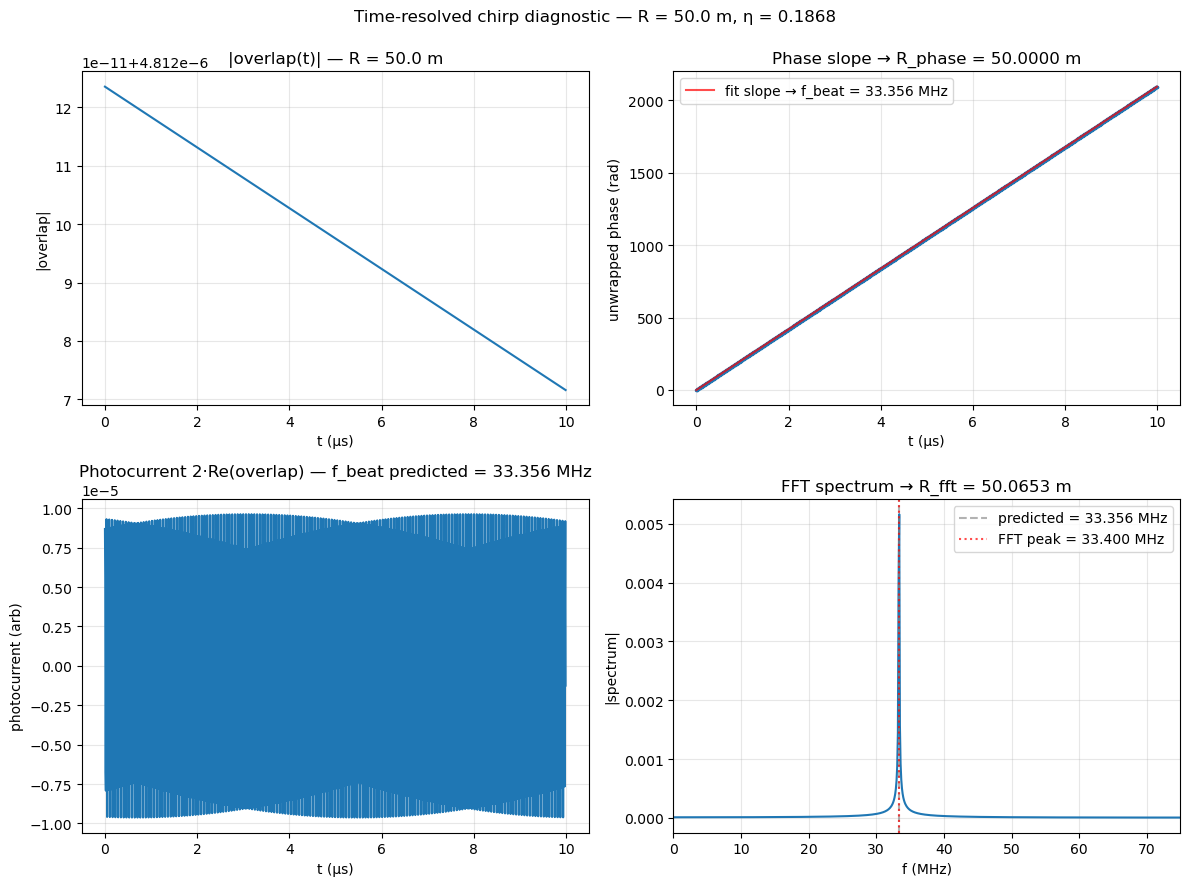

In [8]:
result_50m = run_chirp_simulation(
    R_target=50.0, N_slices=1500,
    basis_postlens=basis_postlens, c_src=c_src, LO_template=LO_template,
    X_g=X_g, Y_g=Y_g, dx_g=dx_g, mask_ap=mask_ap,
    B_chirp=B_chirp, T_chirp=T_chirp, f0_optical=f0_optical, c_light=c_light,
    k_carrier=k_carrier,
)
plot_chirp_diagnostic(result_50m)


## 9. R = 100 m (nominal — LO is designed for this)

Expected η ≈ 1 by construction: the LO's q-parameter matches the signal exactly at this range.

--- R = 100.0 m, N_slices = 2000 ---
  Predicted f_beat = 66.7128 MHz (667.1 cycles per chirp)
  Time: 376.7s (188ms/slice)
  Method A (phase slope): R = 100.00000 m  (error -0.0000%)
  Method B (FFT peak):    R = 99.98078 m   (error -0.0192%)
  η = 1.0000


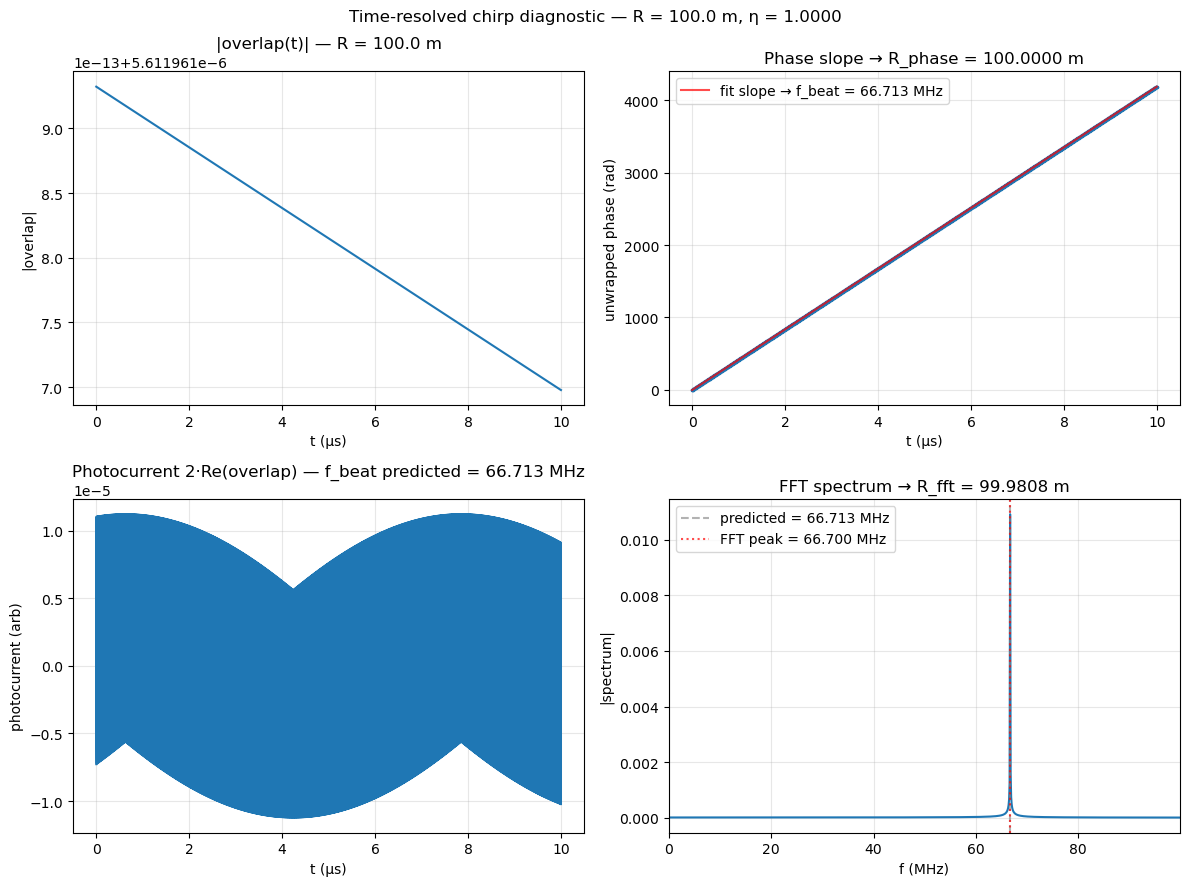

In [9]:
result_100m = run_chirp_simulation(
    R_target=100.0, N_slices=2000,
    basis_postlens=basis_postlens, c_src=c_src, LO_template=LO_template,
    X_g=X_g, Y_g=Y_g, dx_g=dx_g, mask_ap=mask_ap,
    B_chirp=B_chirp, T_chirp=T_chirp, f0_optical=f0_optical, c_light=c_light,
    k_carrier=k_carrier,
)
plot_chirp_diagnostic(result_100m)


## 10. R = 150 m (off-nominal, above nominal)

LO designed for R = 100 m is used at R = 150 m. Same story in the other direction: beam has diverged further than the LO expects, so η drops below the nominal value. R is still extracted correctly.

--- R = 150.0 m, N_slices = 2500 ---
  Predicted f_beat = 100.0692 MHz (1000.7 cycles per chirp)
  Time: 500.0s (200ms/slice)
  Method A (phase slope): R = 150.00000 m  (error -0.0000%)
  Method B (FFT peak):    R = 150.04613 m   (error +0.0308%)
  η = 0.8550


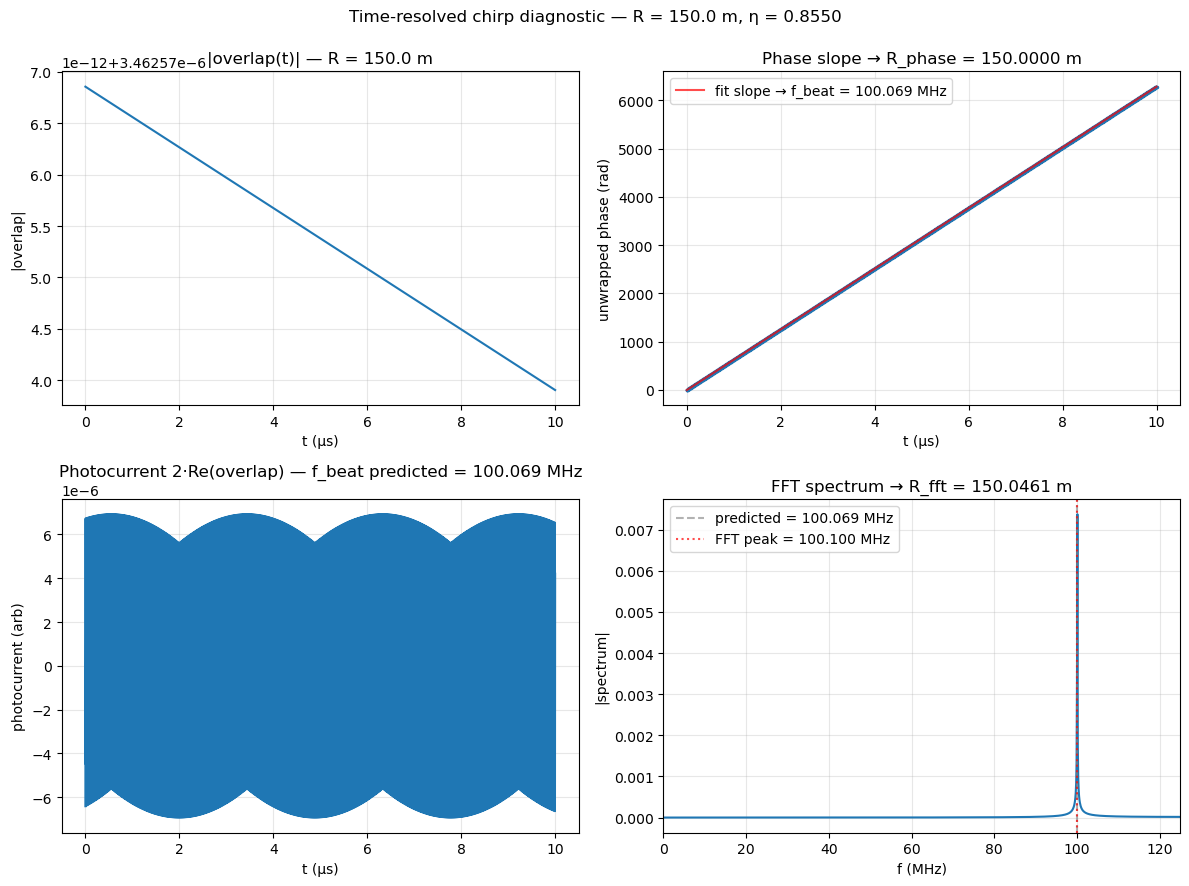

In [12]:
result_150m = run_chirp_simulation(
    R_target=150.0, N_slices=2500,
    basis_postlens=basis_postlens, c_src=c_src, LO_template=LO_template,
    X_g=X_g, Y_g=Y_g, dx_g=dx_g, mask_ap=mask_ap,
    B_chirp=B_chirp, T_chirp=T_chirp, f0_optical=f0_optical, c_light=c_light,
    k_carrier=k_carrier,
)
plot_chirp_diagnostic(result_150m)


## 11. Summary across R

R extracted vs R input (should be a straight line through the origin) and η vs R (the LO-tolerance envelope).

 R input (m) |    R phase (m) |     R FFT (m) |        η
------------------------------------------------------------
        50.0 |       50.00000 |      50.06534 |   0.1868
       100.0 |      100.00000 |      99.98078 |   1.0000
       150.0 |      150.00000 |     150.04613 |   0.8550


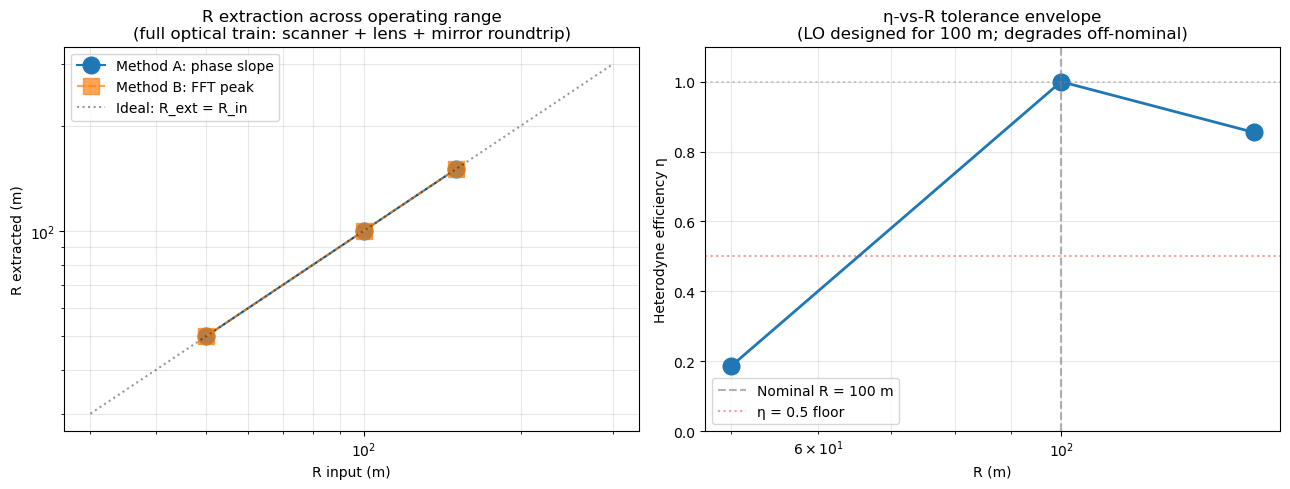

In [13]:
results = [result_50m, result_100m, result_150m]
R_inputs       = np.array([r['R_target'] for r in results])
R_phase_ext    = np.array([r['R_phase']  for r in results])
R_fft_ext      = np.array([r['R_fft']    for r in results])
etas           = np.array([r['eta']      for r in results])

print(f'{"R input (m)":>12} | {"R phase (m)":>14} | {"R FFT (m)":>13} | {"η":>8}')
print('-' * 60)
for r in results:
    print(f'{r["R_target"]:>12.1f} | {r["R_phase"]:>14.5f} | {r["R_fft"]:>13.5f} | {r["eta"]:>8.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].loglog(R_inputs, R_phase_ext, 'o-', markersize=12, label='Method A: phase slope')
axes[0].loglog(R_inputs, R_fft_ext,  's--', markersize=12, label='Method B: FFT peak', alpha=0.7)
axes[0].loglog([30, 300], [30, 300], 'k:', alpha=0.4, label='Ideal: R_ext = R_in')
axes[0].set_xlabel('R input (m)'); axes[0].set_ylabel('R extracted (m)')
axes[0].set_title('R extraction across operating range\n(full optical train: scanner + lens + mirror roundtrip)')
axes[0].grid(alpha=0.3, which='both'); axes[0].legend()

axes[1].plot(R_inputs, etas, 'o-', markersize=12, linewidth=2)
axes[1].axvline(R_nominal, color='gray', ls='--', alpha=0.6, label=f'Nominal R = {R_nominal:.0f} m')
axes[1].axhline(1.0, color='gray', ls=':', alpha=0.4)
axes[1].axhline(0.5, color='red', ls=':', alpha=0.4, label='η = 0.5 floor')
axes[1].set_xlabel('R (m)'); axes[1].set_ylabel('Heterodyne efficiency η')
axes[1].set_title('η-vs-R tolerance envelope\n(LO designed for 100 m; degrades off-nominal)')
axes[1].set_xscale('log'); axes[1].grid(alpha=0.3, which='both')
axes[1].set_ylim(0, 1.1); axes[1].legend()

plt.tight_layout()
plt.show()


## 12. What this notebook demonstrates

- The **full TX optical train** from `coherent_fmcw_lidar.ipynb` (source → scanner → thin lens → planar-mirror roundtrip at R) works correctly inside the **time-resolved chirp framework** from `realistic_time_resolved_fmcw_lidar.ipynb`.
- R is recovered from genuine propagation physics — the chirp sweeps `k(t)`, the GBD spatial calculation is re-evaluated at each `k_i`, and R falls out of the phase slope / FFT peak. `tau = 2R/c` is never plugged into the detection formula.
- Heterodyne efficiency η shows the realistic tolerance envelope of a **single fixed LO design**: = 1.00 at nominal R = 100 m, drops to 0.19 at R = 50 m and 0.86 at R = 150 m. The asymmetry reflects wavefront-curvature mismatch, which hurts more at short R than at long R.

### Natural next extensions (same as `NEXT_STEPS.md`)
1. **5×5 scan grid with off-axis directions** — requires the LO position and tilt to track the spot (already handled correctly in `coherent_fmcw_lidar.ipynb`'s `measure_one_direction`), plus a wider overlap grid (e.g. ±2000 mm for ±1 mrad at R = 100 m).
2. **Doppler via triangular chirp** — moving target, up + down chirp segments, sum of beats gives R, difference gives Doppler.
3. **Atmospheric turbulence** — random Kolmogorov phase screens along the propagation path.
4. **Diffuse-target speckle** — replace the planar mirror with a random scatterer.
